# Regressão Múltipla e Padronização

## Conjunto de dados (_dataset_):

* [Imóveis em São Paulo](http://moodle.pep2.ifsp.edu.br/mod/resource/view.php?id=71270)
* [Referência: Sao Paulo Sale Housing](https://www.kaggle.com/datasets/vsevolodlisachov/sao-paulo-sale-housing
)

In [1]:
# criando função para dimensionar gráfico no Jupyter
rm(list=ls())
library(repr)
grafdim <- function(x=11,y=8) { options(repr.plot.width=x, repr.plot.height=y) }

## Obtenção dos dados

Importação, conversão, ajuste e adequação dos dados.

In [2]:
sp_01 <- read.csv("imoveis_sao_paulo.csv")
sp <- sp_01

## Análise descritiva e adequação dos dados

Avaliação da qualidade e adequação das variáveis; exclusão de variáveis que não colaborem com a modelagem do `preco` dos imóveis.  
Padronização das variáveis consideradas úteis para a modelagem do `preco`.

In [3]:
summary(sp)

      cod             anuncio          preco             condominio     
 Min.   :    1   Length   :16197   Min.   :     1100   Min.   :      0  
 1st Qu.: 4050   N.unique :14228   1st Qu.:   380000   1st Qu.:    500  
 Median : 8099   N.blank  :    0   Median :   880000   Median :    980  
 Mean   : 8099   Min.nchar:   10   Mean   :  1696082   Mean   :   2242  
 3rd Qu.:12148   Max.nchar:  100   3rd Qu.:  1820000   3rd Qu.:   1700  
 Max.   :16197                     Max.   :374000000   Max.   :3300000  
                                                       NAs    :556      
      iptu               area           quartos       banheiros     
 Min.   :       0   Min.   :  10.0   Min.   :0.00   Min.   : 1.000  
 1st Qu.:      50   1st Qu.:  50.0   1st Qu.:2.00   1st Qu.: 1.000  
 Median :     300   Median :  78.0   Median :2.00   Median : 2.000  
 Mean   :    3717   Mean   : 109.8   Mean   :2.47   Mean   : 2.574  
 3rd Qu.:     932   3rd Qu.: 142.0   3rd Qu.:3.00   3rd Qu.: 4.000  
 M

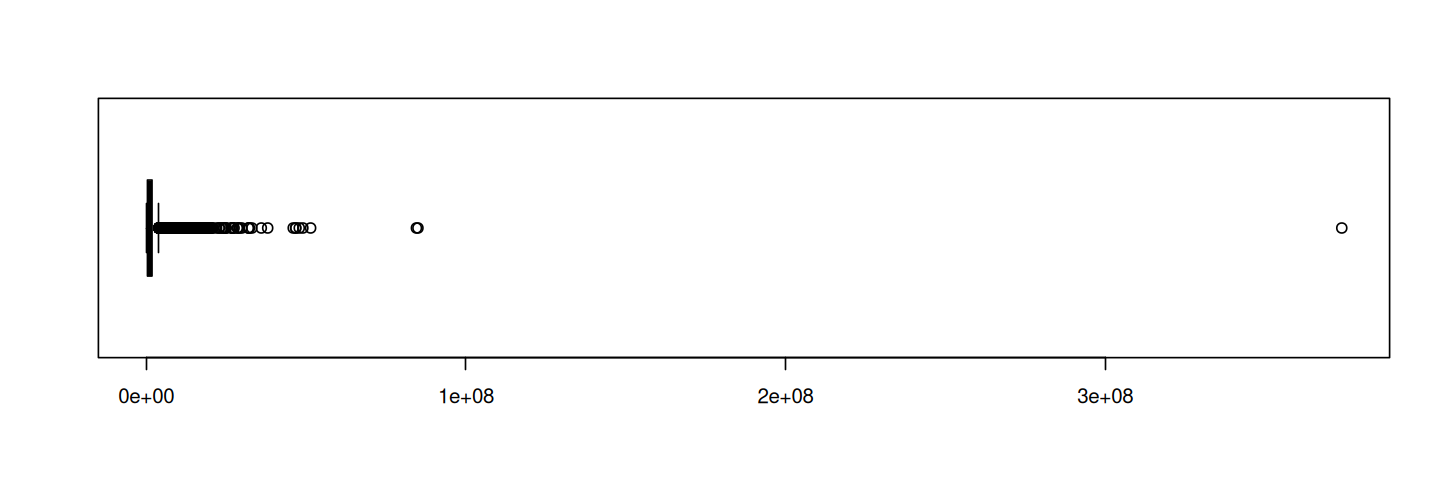

In [4]:
grafdim(12,4)
boxplot(sp$preco, horizontal=TRUE, col="moccasin")

In [5]:
sp[sp$preco > 50000000,]

,cod,anuncio,preco,condominio,iptu,area,quartos,banheiros,vagas,rua,bairro,latitude,longitude,imobiliaria
,<int>,<chr>,<int>,<dbl>,<dbl>,<int>,<int>,<int>,<dbl>,<chr>,<chr>,<dbl>,<dbl>,<chr>
13930,13930,Apartamento com 64m² 2 Dorms 2 Banheiros Próximo ao Metro Sacomã SP,374000000,805,0,64,2,2,1,Rua Américo Samarone,Vila Moinho Velho,-23.60539,-46.60021,Imobiliária Prime Brokers
14572,14572,APARTAMENTO - SUMAREZINHO - SP,51427400,258,132,31,1,1,0,Rua Oscar Caravelas,Sumarezinho,-23.54438,-46.69529,Imóveis Guru
14983,14983,APARTAMENTO - SUMAREZINHO - SP,84523500,600,0,52,2,1,0,Rua Juatuba,Sumarezinho,NA,NA,Leardi Alto De Pinheiros 300
15039,15039,Cobertura duplex em edifício neoclássico no Jardim América,85000000,32000,19870,1262,6,8,10,,Jardim Paulista,NA,NA,Bossa Nova Sotheby'S


In [6]:
sp <- sp[sp$cod != 13930,]
sp <- sp[sp$cod != 14572,]
sp <- sp[sp$cod != 14983,]

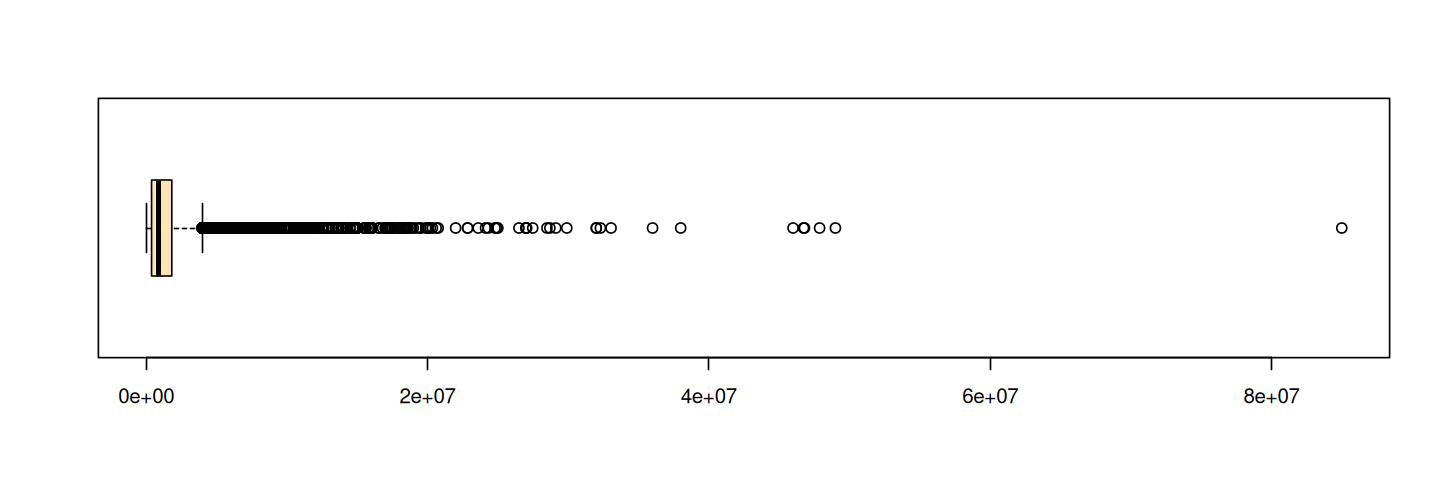

In [7]:
grafdim(12,4)
boxplot(sp$preco, horizontal=TRUE, col="moccasin")

In [8]:
iptu <- sp$iptu
sp$iptu[!is.na(iptu) & sp$iptu > 100000] <- NA
summary(sp$iptu)

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max.     NAs 
      0      50     300    1116     930   87000    1960 

In [9]:
# sp[!is.na(sp$iptu) & sp$iptu > 10000,]

In [10]:
# considerar dado perdido todo condomínio que for superior
# a 10% do preço do imóvel
sp$condominio[!is.na(sp$condominio) & sp$condominio > 0.05*sp$preco] <- NA
sp[!is.na(sp$condominio) & sp$condominio > 20000,]
summary(sp$condominio)

,cod,anuncio,preco,condominio,iptu,area,quartos,banheiros,vagas,rua,bairro,latitude,longitude,imobiliaria
,<int>,<chr>,<int>,<dbl>,<dbl>,<int>,<int>,<int>,<dbl>,<chr>,<chr>,<dbl>,<dbl>,<chr>
13513,13513,"Cobertura Duplex a venda no condomínio Evidence Vila Mariana, 03 dormitórios e 03 vagas.",3850000,35000,2531,287,3,5,3,Rua João Alves dos Santos,Jardim Vila Mariana,-23.59061,-46.62152,Praticis Imóveis
14395,14395,APARTAMENTO DE ALTO PADRÃO JARDIM EUROPA 4 SUÍTES,47875000,24000,5430,750,4,7,6,Rua Escócia,Jardim Europa,-23.57953,-46.68439,Zimmermann Imóveis
14398,14398,Cobertura com 4 quartos à venda em Jardim Guedala - SP,36000000,23000,16670,1200,4,6,10,Rua Joaquim Macedo,Jardim Guedala,NA,NA,Local Imóveis - Jardins
15011,15011,"Apartamento Garden à venda, 893 m² por R$ 23.605.000,00 - Vila Olímpia - São Paulo/SP",23605000,22277,11575,893,5,6,6,Rua Gomes de Carvalho,Vila Olímpia,-23.60134,-46.67636,Tricase Empreendimentos E Negocios Imobiliarios Ltda
15039,15039,Cobertura duplex em edifício neoclássico no Jardim América,85000000,32000,19870,1262,6,8,10,,Jardim Paulista,NA,NA,Bossa Nova Sotheby'S


   Min. 1st Qu.  Median    Mean 3rd Qu.    Max.     NAs 
      0     500     970    1361    1650   35000     840 

Loading required package: carData



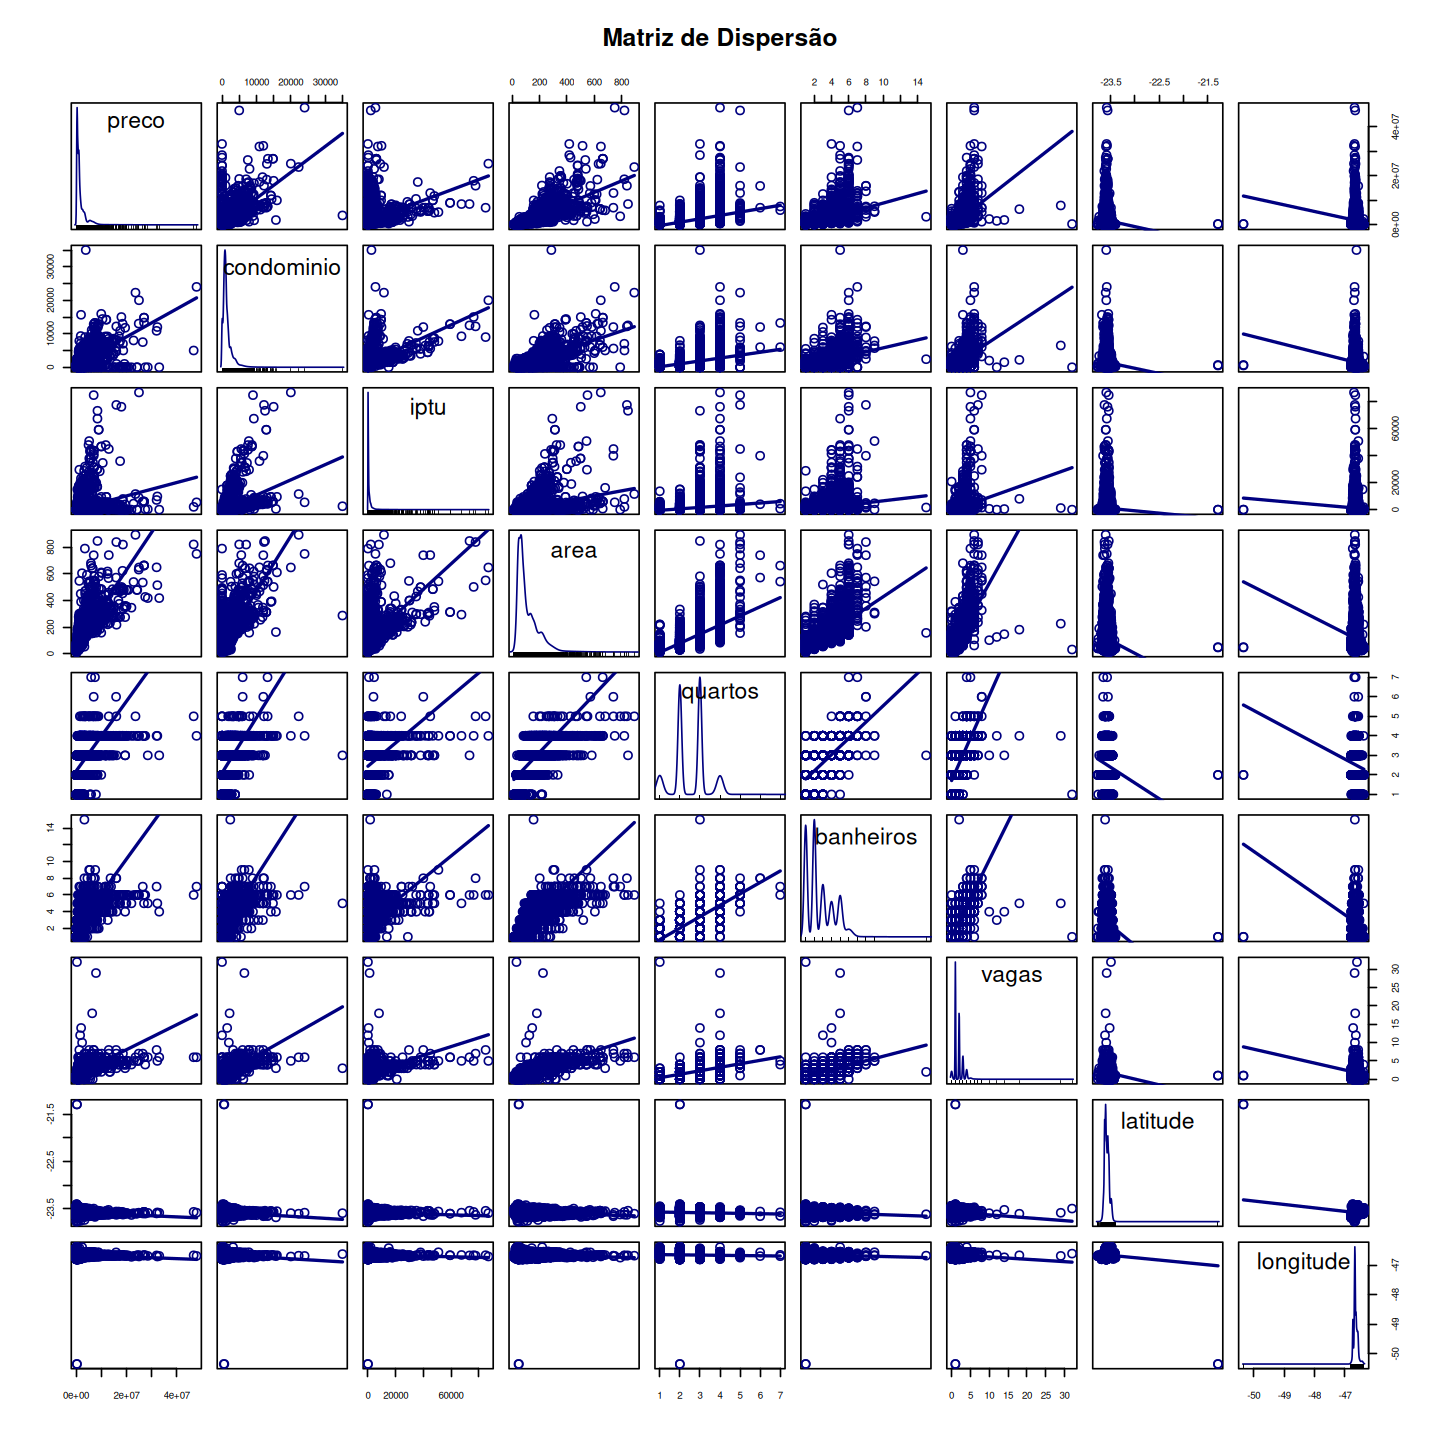

In [11]:
library(car)
grafdim(12,12)
variaveis <- c("preco","condominio","iptu","area","quartos",
               "banheiros","vagas","latitude","longitude")
scatterplotMatrix(sp[ , variaveis],
                  smooth=FALSE, col="navyblue", cex=1.2, cex.labels=1.7, cex.axis=0.7,
                  main="Matriz de Dispersão")

## Construção do modelo base para o `preco`

In [12]:
mod01 <- lm(formula= preco ~ condominio + iptu + area + 
            quartos + banheiros + vagas + latitude + longitude,
            data=sp)

In [13]:
summary(mod01)


Call:
lm(formula = preco ~ condominio + iptu + area + quartos + banheiros + 
    vagas + latitude + longitude, data = sp)

Residuals:
      Min        1Q    Median        3Q       Max 
-13686175   -307134     12062    272183  27815397 

Coefficients:
              Estimate Std. Error t value Pr(>|t|)    
(Intercept)  1.500e+07  9.744e+06   1.539    0.124    
condominio   1.845e+02  1.346e+01  13.709  < 2e-16 ***
iptu        -3.609e+01  3.958e+00  -9.117  < 2e-16 ***
area         2.465e+04  3.492e+02  70.571  < 2e-16 ***
quartos     -4.709e+05  2.362e+04 -19.933  < 2e-16 ***
banheiros   -1.790e+04  1.621e+04  -1.104    0.269    
vagas        7.430e+04  1.701e+04   4.367 1.27e-05 ***
latitude     2.208e+05  2.338e+05   0.944    0.345    
longitude    2.131e+05  1.567e+05   1.360    0.174    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 1330000 on 11001 degrees of freedom
  (5184 observations deleted due to missingness)
Multiple R-squared: 

In [14]:
mod02 <- lm(formula= preco ~ condominio + iptu + area + 
            quartos +  vagas, data=sp)

In [15]:
summary(mod02)


Call:
lm(formula = preco ~ condominio + iptu + area + quartos + vagas, 
    data = sp)

Residuals:
      Min        1Q    Median        3Q       Max 
-14392582   -342725     31600    299319  49038783 

Coefficients:
              Estimate Std. Error t value Pr(>|t|)    
(Intercept) -1.164e+05  4.410e+04  -2.639  0.00833 ** 
condominio   2.175e+02  1.359e+01  16.010  < 2e-16 ***
iptu        -3.714e+01  4.111e+00  -9.036  < 2e-16 ***
area         2.609e+04  3.252e+02  80.246  < 2e-16 ***
quartos     -5.346e+05  2.271e+04 -23.542  < 2e-16 ***
vagas        1.334e+04  1.694e+04   0.787  0.43102    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 1538000 on 13368 degrees of freedom
  (2820 observations deleted due to missingness)
Multiple R-squared:  0.6667,	Adjusted R-squared:  0.6666 
F-statistic:  5348 on 5 and 13368 DF,  p-value: < 2.2e-16


In [16]:
mod03 <- lm(formula= preco ~ condominio + iptu + area + 
            quartos + banheiros, data=sp)
summary(mod03)


Call:
lm(formula = preco ~ condominio + iptu + area + quartos + banheiros, 
    data = sp)

Residuals:
      Min        1Q    Median        3Q       Max 
-14776641   -317359     23391    278709  48700427 

Coefficients:
              Estimate Std. Error t value Pr(>|t|)    
(Intercept) -1.234e+05  4.250e+04  -2.904  0.00369 ** 
condominio   2.234e+02  1.329e+01  16.805  < 2e-16 ***
iptu        -3.727e+01  4.052e+00  -9.199  < 2e-16 ***
area         2.711e+04  3.220e+02  84.196  < 2e-16 ***
quartos     -4.584e+05  2.401e+04 -19.094  < 2e-16 ***
banheiros   -1.044e+05  1.543e+04  -6.762 1.41e-11 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 1517000 on 13771 degrees of freedom
  (2417 observations deleted due to missingness)
Multiple R-squared:  0.6701,	Adjusted R-squared:   0.67 
F-statistic:  5596 on 5 and 13771 DF,  p-value: < 2.2e-16


## Melhorias no modelo base até modelo julgado melhor

Evolução do modelo pela elenco da variáveis (_features_) mais adequadas de modo a melhor explicar o comportamento do `preco`.

In [17]:
med_condominio <- mean(sp$condominio, na.rm=TRUE)
des_condominio <- sd(sp$condominio, na.rm=TRUE)

med_iptu <- mean(sp$iptu, na.rm=TRUE)
des_iptu <- sd(sp$iptu, na.rm=TRUE)

med_area <- mean(sp$area, na.rm=TRUE)
des_area <- sd(sp$area, na.rm=TRUE)

med_quartos <- mean(sp$quartos, na.rm=TRUE)
des_quartos <- sd(sp$quartos, na.rm=TRUE)

med_banheiros <- mean(sp$banheiros, na.rm=TRUE)
des_banheiros <- sd(sp$banheiros, na.rm=TRUE)
sp <- sp[, c("preco", "condominio", "iptu", "area", "quartos", "banheiros")]
sp_nao_padronizado <- sp

In [18]:
sp$condominio <- (sp$condominio - med_condominio) / des_condominio
sp$iptu <- (sp$iptu - med_iptu) / des_iptu
sp$area <- (sp$area - med_area) / des_area
sp$quartos <- (sp$quartos - med_quartos) / des_quartos
sp$banheiros <- (sp$banheiros - med_banheiros) / des_banheiros

In [19]:
summary(sp)

     preco            condominio           iptu               area        
 Min.   :    1100   Min.   :-0.8896   Min.   :-0.31369   Min.   :-1.1549  
 1st Qu.:  380000   1st Qu.:-0.5629   1st Qu.:-0.29964   1st Qu.:-0.6923  
 Median :  880000   Median :-0.2558   Median :-0.22937   Median :-0.3627  
 Mean   : 1664906   Mean   : 0.0000   Mean   : 0.00000   Mean   : 0.0000  
 3rd Qu.: 1818000   3rd Qu.: 0.1886   3rd Qu.:-0.05232   3rd Qu.: 0.3717  
 Max.   :85000000   Max.   :21.9812   Max.   :24.13714   Max.   :13.3253  
                    NAs    :840       NAs    :1960                        
    quartos          banheiros      
 Min.   :-2.9053   Min.   :-0.9985  
 1st Qu.:-0.5531   1st Qu.:-0.9985  
 Median :-0.5531   Median :-0.3643  
 Mean   : 0.0000   Mean   : 0.0000  
 3rd Qu.: 0.6231   3rd Qu.: 0.9043  
 Max.   : 6.5037   Max.   : 7.8813  
                                    

In [20]:
mod04 <- lm(formula= preco ~ condominio + iptu + area + 
            quartos + banheiros, data=sp)
summary(mod04)


Call:
lm(formula = preco ~ condominio + iptu + area + quartos + banheiros, 
    data = sp)

Residuals:
      Min        1Q    Median        3Q       Max 
-14776641   -317359     23391    278709  48700427 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept)  1716874      12994 132.133  < 2e-16 ***
condominio    341851      20342  16.805  < 2e-16 ***
iptu         -132627      14418  -9.199  < 2e-16 ***
area         2344406      27844  84.196  < 2e-16 ***
quartos      -389763      20412 -19.094  < 2e-16 ***
banheiros    -164539      24332  -6.762 1.41e-11 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 1517000 on 13771 degrees of freedom
  (2417 observations deleted due to missingness)
Multiple R-squared:  0.6701,	Adjusted R-squared:   0.67 
F-statistic:  5596 on 5 and 13771 DF,  p-value: < 2.2e-16


## Comparação da qualidade dos modelos

In [21]:
summary(sp)

     preco            condominio           iptu               area        
 Min.   :    1100   Min.   :-0.8896   Min.   :-0.31369   Min.   :-1.1549  
 1st Qu.:  380000   1st Qu.:-0.5629   1st Qu.:-0.29964   1st Qu.:-0.6923  
 Median :  880000   Median :-0.2558   Median :-0.22937   Median :-0.3627  
 Mean   : 1664906   Mean   : 0.0000   Mean   : 0.00000   Mean   : 0.0000  
 3rd Qu.: 1818000   3rd Qu.: 0.1886   3rd Qu.:-0.05232   3rd Qu.: 0.3717  
 Max.   :85000000   Max.   :21.9812   Max.   :24.13714   Max.   :13.3253  
                    NAs    :840       NAs    :1960                        
    quartos          banheiros      
 Min.   :-2.9053   Min.   :-0.9985  
 1st Qu.:-0.5531   1st Qu.:-0.9985  
 Median :-0.5531   Median :-0.3643  
 Mean   : 0.0000   Mean   : 0.0000  
 3rd Qu.: 0.6231   3rd Qu.: 0.9043  
 Max.   : 6.5037   Max.   : 7.8813  
                                    

In [22]:
eam <- function(observado, predito) {
    if (length(observado) != length(predito)) { return (NA) }
    return(sum(abs(observado - predito)) / length(observado))
}
eam_res <- function(residuos) { sum(abs(residuos)/length(residuos)) }

In [23]:
eqm <- function(observado, predito) {
    if (length(observado) != length(predito)) { return (NA) }
    return(sum((observado - predito) * (observado - predito) ) / length(observado))
}
eqm_res <- function(residuos) { sum(residuos * residuos) / length(residuos) }

In [24]:
observados <- sp$preco[ !is.na(sp$condominio) & !is.na(sp$iptu) ]

In [25]:
eam3     <- eam(observados, mod03$fitted.values)
eam3_res <- eam_res(mod03$residuals)

eqm3     <- eqm(observados, mod03$fitted.values)
eqm3_res <- eqm_res(mod03$residuals)

print(paste(eam3,eam3_res))
print(paste(eqm3,eqm3_res))

[1] "652663.498554797 652663.498554797"
[1] "2300841712099.91 2300841712099.91"


In [26]:
eam4     <- eam(observados, mod04$fitted.values)
eam4_res <- eam_res(mod04$residuals)
eqm4     <- eqm(observados, mod04$fitted.values)
eqm4_res <- eqm_res(mod04$residuals)

print(paste(eam4,eam4_res))
print(paste(eqm4,eqm4_res))

[1] "652663.498554797 652663.498554797"
[1] "2300841712099.91 2300841712099.91"


In [27]:
print(paste("mod03: eam=",eam3,"  eqm=",eqm3,"   R²=",round(summary(mod03)$adj.r.squared,4)))
print(paste("mod04: eam=",eam4,"  eqm=",eqm4,"   R²=",round(summary(mod04)$adj.r.squared,4)))

[1] "mod03: eam= 652663.498554797   eqm= 2300841712099.91    R²= 0.67"
[1] "mod04: eam= 652663.498554797   eqm= 2300841712099.91    R²= 0.67"


Modelo 3 (sem padronização) e Modelo 4 (variáveis padronizadas) são iguais, apresentam os mesmo valores e erros quadráticos e absolutos médios.

Modelo com variáveis ao quadrado e interações de 2º nível:

In [28]:
mod05 <- lm(formula=preco ~ . + (.)^2 + (.)^3 + 
            I(condominio^2) + I(iptu^2) + I(area^2) + I(quartos^2) + 
            I(banheiros^2), data=sp)

In [29]:
summary(mod05)


Call:
lm(formula = preco ~ . + (.)^2 + (.)^3 + I(condominio^2) + I(iptu^2) + 
    I(area^2) + I(quartos^2) + I(banheiros^2), data = sp)

Residuals:
      Min        1Q    Median        3Q       Max 
-17941299   -291422    -24197    233748  48414801 

Coefficients:
                             Estimate Std. Error t value Pr(>|t|)    
(Intercept)                   1600048      21418  74.706  < 2e-16 ***
condominio                     413618      37836  10.932  < 2e-16 ***
iptu                           -62914      42564  -1.478 0.139402    
area                          1715620      50034  34.289  < 2e-16 ***
quartos                       -124378      23842  -5.217 1.85e-07 ***
banheiros                       82717      33254   2.487 0.012879 *  
I(condominio^2)                 22338       3401   6.568 5.27e-11 ***
I(iptu^2)                        8369       3088   2.710 0.006739 ** 
I(area^2)                       52027      15570   3.341 0.000836 ***
I(quartos^2)                  -131

In [30]:
mod06 <- lm(formula=preco ~ . + (.)^2 + (.)^3 + 
            I(condominio^2) + I(iptu^2) + I(area^2) + I(quartos^2) + 
            I(banheiros^2) 
            - iptu:area:quartos - iptu - condominio:area:quartos, data=sp)

In [31]:
summary(mod06)


Call:
lm(formula = preco ~ . + (.)^2 + (.)^3 + I(condominio^2) + I(iptu^2) + 
    I(area^2) + I(quartos^2) + I(banheiros^2) - iptu:area:quartos - 
    iptu - condominio:area:quartos, data = sp)

Residuals:
      Min        1Q    Median        3Q       Max 
-17928822   -292304    -23608    231992  48417814 

Coefficients:
                             Estimate Std. Error t value Pr(>|t|)    
(Intercept)                   1604603      20899  76.778  < 2e-16 ***
condominio                     401463      36998  10.851  < 2e-16 ***
area                          1707952      49698  34.367  < 2e-16 ***
quartos                       -123157      23789  -5.177 2.29e-07 ***
banheiros                       78247      33106   2.363 0.018118 *  
I(condominio^2)                 22575       3387   6.664 2.76e-11 ***
I(iptu^2)                        7545       3031   2.489 0.012807 *  
I(area^2)                       52640      15518   3.392 0.000695 ***
I(quartos^2)                  -130862      223

In [32]:
eam6     <- eam(observados, mod06$fitted.values)
eam6_res <- eam_res(mod06$residuals)

eqm6     <- eqm(observados, mod06$fitted.values)
eqm6_res <- eqm_res(mod03$residuals)

print(paste(eam6,eam6_res))
print(paste(eqm6,eqm6_res))

[1] "613419.043538644 613419.043538644"
[1] "1948407466880.1 2300841712099.91"


In [33]:
print(paste("mod04: eam=",eam4,"  eqm=",eqm4,"   R²=",round(summary(mod04)$adj.r.squared,4)))
print(paste("mod06: eam=",eam6,"  eqm=",eqm6,"   R²=",round(summary(mod06)$adj.r.squared,4)))

[1] "mod04: eam= 652663.498554797   eqm= 2300841712099.91    R²= 0.67"
[1] "mod06: eam= 613419.043538644   eqm= 1948407466880.1    R²= 0.7201"


## Conclusões

In [48]:
caso <- sp_nao_padronizado[5,]
caso

,preco,condominio,iptu,area,quartos,banheiros
,<int>,<dbl>,<dbl>,<int>,<int>,<int>
5,170000,420,55,35,2,1


In [49]:
caso$banheiros <- 2
caso$area      <- 60

In [50]:
caso$condominio <- (caso$condominio - med_condominio) / des_condominio
caso$iptu <- (caso$iptu - med_iptu) / des_iptu
caso$area <- (caso$area - med_area) / des_area
caso$quartos <- (caso$quartos - med_quartos) / des_quartos
caso$banheiros <- (caso$banheiros - med_banheiros) / des_banheiros

In [51]:
caso

,preco,condominio,iptu,area,quartos,banheiros
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
5,170000,-0.6151735,-0.2982299,-0.5766613,-0.5530601,-0.3642532


In [52]:
preco <- predict(mod06,newdata=caso)

In [53]:
cat("O preço modelado para o caso é de ",round(preco,2))

O preço modelado para o caso é de  445196.8